# Graph 8: Where does the best model go wrong? (error by hour)
Run `01_data_processing.ipynb` and `08_modelling.ipynb` first.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
saved = joblib.load("processed/model_results.joblib")
best_name, predictions = saved["best_name"], saved["predictions"]
test, y_test = saved["test"], saved["y_test"]

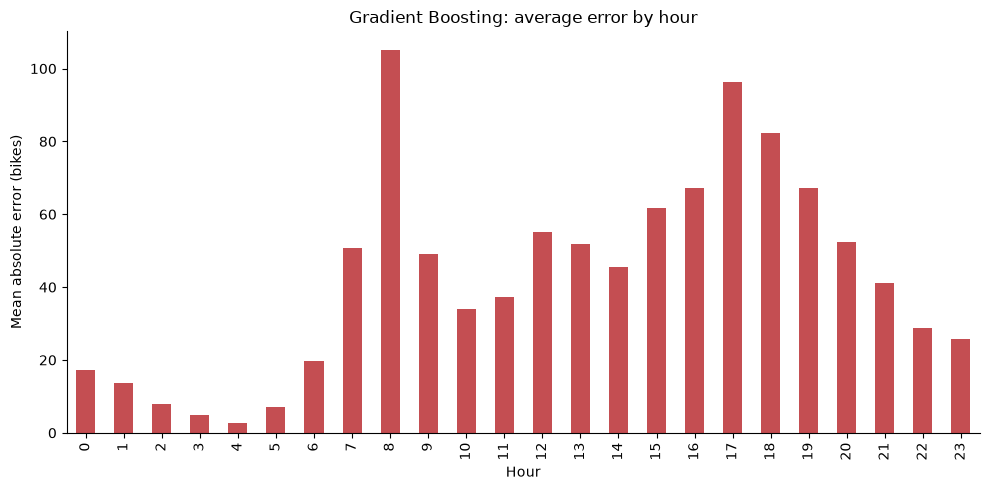

In [3]:
err = pd.DataFrame({"hr": test["hr"].values, "abs_error": np.abs(y_test.values - predictions[best_name])})
err.groupby("hr")["abs_error"].mean().plot(kind="bar", color="#C44E52")
plt.title(f"{best_name}: average error by hour"); plt.xlabel("Hour"); plt.ylabel("Mean absolute error (bikes)")
plt.tight_layout(); plt.savefig("figures/08_error_by_hour.png", dpi=150); plt.show()